## Credit Risk Analysis & Predictive Modeling

An end-to-end data science and risk modeling framework designed to assess borrower creditworthiness, predict loan defaults, and quantify expected financial loss for lending portfolios.

#### Project Overview
Financial institutions face significant exposure to loan defaults. This repository implements a complete quantitative risk pipeline—from exploratory data analysis and feature engineering to machine learning classification and model evaluation—to help minimize credit losses while maintaining healthy loan approval rates.

#### Key Features & Methodology
* **Data Preprocessing & Cleaning:** Handled missing values, addressed extreme outliers, and performed rigorous exploratory data analysis (EDA).
* **Feature Engineering:** Built domain-specific risk indicators (such as debt-to-income ratios and utilization metrics) and applied encoding techniques.
* **Machine Learning Models:** Trained and compared multiple classification algorithms (e.g., Logistic Regression, Random Forest, XGBoost) to predict borrower default risk.
* **Handling Class Imbalance:** Applied resampling strategies and threshold tuning to account for skewed default distributions.
* **Model Evaluation:** Assessed performance using ROC-AUC, Precision-Recall, confusion matrices, and business-centric cost-benefit metrics.

#### Tech Stack
* **Language:** Python
* **Libraries:** `pandas`, `NumPy`, `scikit-learn`, `XGBoost`, `statsmodels`, `matplotlib`, `Seaborn`
* **Environment:** Jupyter Notebook / Python Scripts

## Step 1: Import libraries

In [24]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Step 2: Load the dataset

In [25]:
def generate_ethiopian_risk_data(num_rows=10000):
    # Set seed for reproducibility inside function scope
    np.random.seed(42)

    # 1. Basic Categories
    sectors = ['Manufacturing', 'Agriculture', 'Construction', 'Export', 'Retail', 'Mortgage', 'Personal']
    customer_types = ['Corporate', 'SME', 'Individual', 'Cooperatives']
    
    # Weights for a typical commercial loan book
    sector_weights = [0.20, 0.15, 0.20, 0.15, 0.10, 0.15, 0.05]
    
    # 2. Primary Columns
    data = {
        'Loan_ID': [f'L-{i:06d}' for i in range(1, num_rows + 1)],
        'Sector': np.random.choice(sectors, num_rows, p=sector_weights),
        'Customer_Type': np.random.choice(customer_types, num_rows),
        'Outstanding_Balance': np.random.lognormal(mean=12, sigma=1.5, size=num_rows).round(2)
    }
    
    df = pd.DataFrame(data)

    # 3. Sector-Specific Interest Rates (EIR) and Collateral
    sector_rates = {
        'Manufacturing': 14.5, 'Agriculture': 15.5, 'Construction': 15.0, 
        'Export': 13.5, 'Retail': 16.5, 'Mortgage': 12.5, 'Personal': 18.0
    }
    df['EIR'] = df['Sector'].map(sector_rates) + np.random.uniform(-1, 1, num_rows).round(2)

    # 4. Generate Dates (within the last 5 years)
    start_date = datetime(2021, 1, 1)
    # Vectorized / List comprehension approach for dates
    rand_days_origination = np.random.randint(0, 1500, size=num_rows)
    df['Origination_Date'] = [start_date + timedelta(days=int(d)) for d in rand_days_origination]
    
    # Maturity is 15-20 years for Mortgage, 1-7 years for others
    maturity_years = np.where(df['Sector'] == 'Mortgage', 20, np.random.randint(1, 8, size=num_rows))
    df['Maturity_Date'] = [orig + timedelta(days=int(m * 365)) for orig, m in zip(df['Origination_Date'], maturity_years)]

    # 5. Days Past Due (DPD) and ECL Staging Logic
    dpd_probs = [0.85, 0.10, 0.05] 
    stages = np.random.choice([1, 2, 3], num_rows, p=dpd_probs)
    
    dpd_list = np.zeros(num_rows, dtype=int)
    mask_s1 = (stages == 1)
    mask_s2 = (stages == 2)
    mask_s3 = (stages == 3)
    
    dpd_list[mask_s1] = np.random.randint(0, 30, size=mask_s1.sum())
    dpd_list[mask_s2] = np.random.randint(31, 90, size=mask_s2.sum())
    dpd_list[mask_s3] = np.random.randint(91, 365, size=mask_s3.sum())
            
    df['Days_Past_Due'] = dpd_list
    df['ECL_Stage'] = stages

    # 6. Collateral Value (LTV Ratios) 
    ltv_map = {
        'Corporate': 0.8, 
        'SME': 0.9, 
        'Individual': 1.0, 
        'Cooperatives': 0.85,
        'Mortgage': 0.7
    }
    
    # Map LTV based on Customer_Type safely
    ltv_ratios = df['Customer_Type'].map(ltv_map).fillna(0.8)
    df['Collateral_Value'] = (df['Outstanding_Balance'] / ltv_ratios) * np.random.uniform(0.9, 1.1, num_rows)
    df['Collateral_Value'] = df['Collateral_Value'].round(2)
    
    # Personal loans often unsecured
    df.loc[df['Sector'] == 'Personal', 'Collateral_Value'] = 0.2

    return df

# Generate and view
large_loan_book = generate_ethiopian_risk_data(10000)

print(f"Dataset used with {len(large_loan_book)} rows.")
print(large_loan_book.head())

Dataset used with 10000 rows.
    Loan_ID         Sector Customer_Type  Outstanding_Balance    EIR  \
0  L-000001   Construction    Individual           2025138.34  14.29   
1  L-000002       Personal  Cooperatives            162207.34  17.70   
2  L-000003         Retail  Cooperatives             47714.79  16.67   
3  L-000004         Export           SME            195737.16  12.78   
4  L-000005  Manufacturing     Corporate             71267.74  15.21   

  Origination_Date Maturity_Date  Days_Past_Due  ECL_Stage  Collateral_Value  
0       2022-01-29    2024-01-29             63          2        1902910.21  
1       2024-09-29    2025-09-29             13          1              0.20  
2       2022-06-14    2025-06-13              9          1          60932.93  
3       2024-12-11    2030-12-10             24          1         197610.14  
4       2024-06-08    2028-06-07             16          1          81920.10  


## Step 3: Descriptive Portfolio Analysis

### A. Data Cleaning & Feature Engineering


Loan Segmentation (Exposure % by Sector):
 Sector
Agriculture      0.1463
Construction     0.2130
Export           0.1421
Manufacturing    0.1933
Mortgage         0.1681
Personal         0.0461
Retail           0.0912
Name: Outstanding_Balance, dtype: float64

Default Trends (Rate by Sector):
 Sector
Agriculture      0.0476
Construction     0.0546
Export           0.0491
Manufacturing    0.0470
Mortgage         0.0497
Personal         0.0380
Retail           0.0476
Name: Loan_ID, dtype: float64

Average LGD by Sector:
 Sector
Agriculture      0.2044
Construction     0.2066
Export           0.2107
Manufacturing    0.2062
Mortgage         0.2072
Personal         1.0000
Retail           0.2072
Name: LGD, dtype: float64

Portfolio Summary:
                Exposure %  Default Rate  Avg LGD
Sector                                          
Agriculture        0.1463        0.0476   0.2044
Construction       0.2130        0.0546   0.2066
Export             0.1421        0.0491   0.2107
Manufac

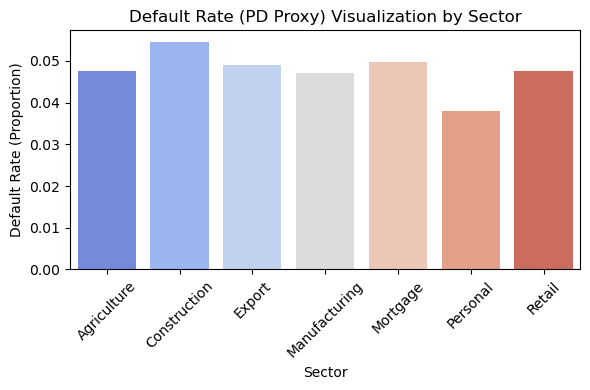


--- Logistic Regression Odds Ratios ---
             Feature  Coefficient  Odds_Ratio  Pct_Change_in_Odds_%
       Days_Past_Due     0.211682    1.235755             23.575485
 Outstanding_Balance     0.000002    1.000002              0.000200
    Collateral_Value    -0.000001    0.999999             -0.000100
     Sector_Personal    -0.006673    0.993349             -0.665078
       Sector_Retail    -0.009358    0.990686             -0.931435
       Sector_Export    -0.013819    0.986276             -1.372396
     Sector_Mortgage    -0.014572    0.985534             -1.446634
 Sector_Construction    -0.019985    0.980213             -1.978662
Sector_Manufacturing    -0.020140    0.980061             -1.993854


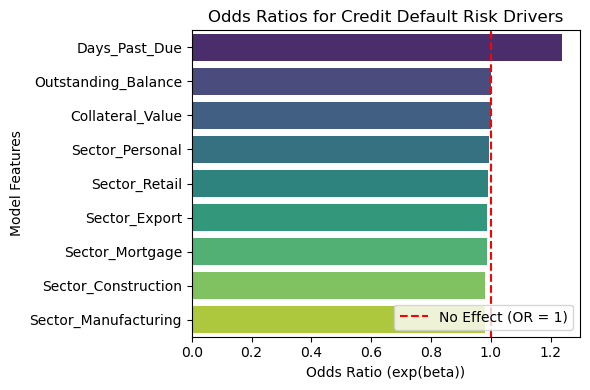

In [26]:
# Step 1: Data Cleaning & Feature Engineering
df = large_loan_book.copy()

# Ensure numeric columns are properly typed
numeric_cols = ['Outstanding_Balance', 'EIR', 'Days_Past_Due', 'Collateral_Value']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

# Handle missing collateral values safely
df['Collateral_Value'] = df['Collateral_Value'].fillna(0)

# Create Loan-to-Value (LTV) ratio
df['LTV'] = np.where(
    df['Collateral_Value'] > 0,
    df['Outstanding_Balance'] / df['Collateral_Value'],
    99.9  # Representing highly unsecured / infinite LTV
)

# Step 2: Loan Segmentation (Exposure by Sector)
exposure_by_sector = df.groupby('Sector')['Outstanding_Balance'].sum()
exposure_pct = (exposure_by_sector / exposure_by_sector.sum()).round(4)
print("\nLoan Segmentation (Exposure % by Sector):\n", exposure_pct)

# Step 3: Default Trends & PD Calculation by Sector
df['Default'] = np.where(df['ECL_Stage'] == 3, 1, 0) 

default_counts = df[df['ECL_Stage'] == 3].groupby('Sector')['Loan_ID'].count()
total_counts = df.groupby('Sector')['Loan_ID'].count()
default_rate = (default_counts / total_counts).fillna(0).round(4)
print("\nDefault Trends (Rate by Sector):\n", default_rate)

# Step 4: Recovery Rates & Loss Given Default (LGD) by Segment
df['Recovery_Rate'] = np.where(
    df['Collateral_Value'] > 0,
    np.minimum((df['Collateral_Value'] * 0.7) / df['Outstanding_Balance'], 1.0),
    0.15  
)
df['LGD'] = 1 - df['Recovery_Rate']

lgd_by_sector = df.groupby('Sector')['LGD'].mean().round(4)
print("\nAverage LGD by Sector:\n", lgd_by_sector)

# Step 5: Portfolio Summary Table
portfolio_summary = pd.DataFrame({
    "Exposure %": exposure_pct,
    "Default Rate": default_rate,
    "Avg LGD": lgd_by_sector
}).fillna(0)

print("\nPortfolio Summary:\n", portfolio_summary)

# Visualization of Default Rates by Sector 
plt.figure(figsize=(6, 4))
sns.barplot(
    x=default_rate.index,
    y=default_rate.values,
    hue=default_rate.index,
    palette="coolwarm",
    legend=False
)
plt.title("Default Rate (PD Proxy) Visualization by Sector")
plt.ylabel("Default Rate (Proportion)")
plt.xlabel("Sector")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Logistic Regression Odds Ratio Analysis
or_data = {
    'Feature': [
        'Days_Past_Due',
        'Outstanding_Balance',
        'Collateral_Value',
        'Sector_Personal',
        'Sector_Retail',
        'Sector_Export',
        'Sector_Mortgage',
        'Sector_Construction',
        'Sector_Manufacturing',
    ],
    'Coefficient': [
        0.211682,
        0.000002,
        -0.000001,
        -0.006673,
        -0.009358,
        -0.013819,
        -0.014572,
        -0.019985,
        -0.020140,
    ],
}
df_or = pd.DataFrame(or_data)

# Convert Log-Odds to Odds Ratios
df_or['Odds_Ratio'] = np.exp(df_or['Coefficient'])
df_or['Pct_Change_in_Odds_%'] = (df_or['Odds_Ratio'] - 1) * 100
df_or = df_or.sort_values(by='Odds_Ratio', ascending=False)

print("\n--- Logistic Regression Odds Ratios ---")
print(df_or[['Feature', 'Coefficient', 'Odds_Ratio', 'Pct_Change_in_Odds_%']].to_string(index=False))

# Visualize Odds Ratios
plt.figure(figsize=(6, 4))
sns.barplot(
    x='Odds_Ratio',
    y='Feature',
    data=df_or,
    hue='Feature',
    palette='viridis',
    legend=False,
)
plt.axvline(x=1, color='red', linestyle='--', label='No Effect (OR = 1)')
plt.title('Odds Ratios for Credit Default Risk Drivers')
plt.xlabel('Odds Ratio (exp(beta))')
plt.ylabel('Model Features')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Step 4: Loss Given Default (LGD) Results

Classification Report:
               precision    recall  f1-score   support

           1       0.99      1.00      0.99      1700
           2       1.00      0.91      0.95       212
           3       1.00      1.00      1.00        88

    accuracy                           0.99      2000
   macro avg       1.00      0.97      0.98      2000
weighted avg       0.99      0.99      0.99      2000


Average LGD by Sector (Series):
 Sector
Agriculture      0.204
Construction     0.207
Export           0.211
Manufacturing    0.206
Mortgage         0.207
Personal         1.000
Retail           0.207
Name: LGD, dtype: float64


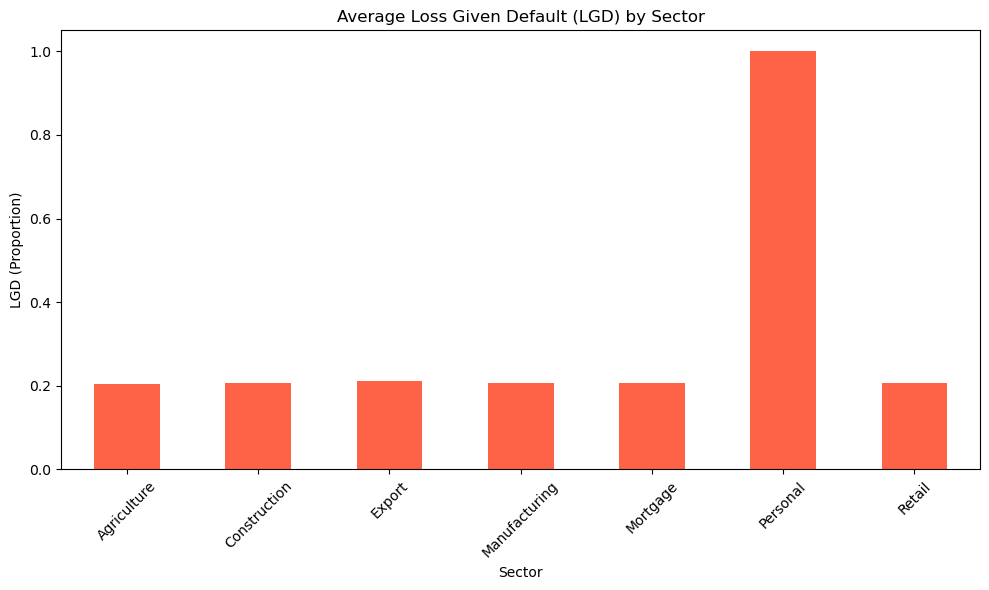


Combined PD-LGD Dashboard DataFrame:
                   PD    LGD
Agriculture    0.052  0.161
Construction   0.047  0.159
Export         0.059  0.156
Manufacturing  0.046  0.159
Mortgage       0.053  0.161
Personal       0.063  1.000
Retail         0.046  0.153


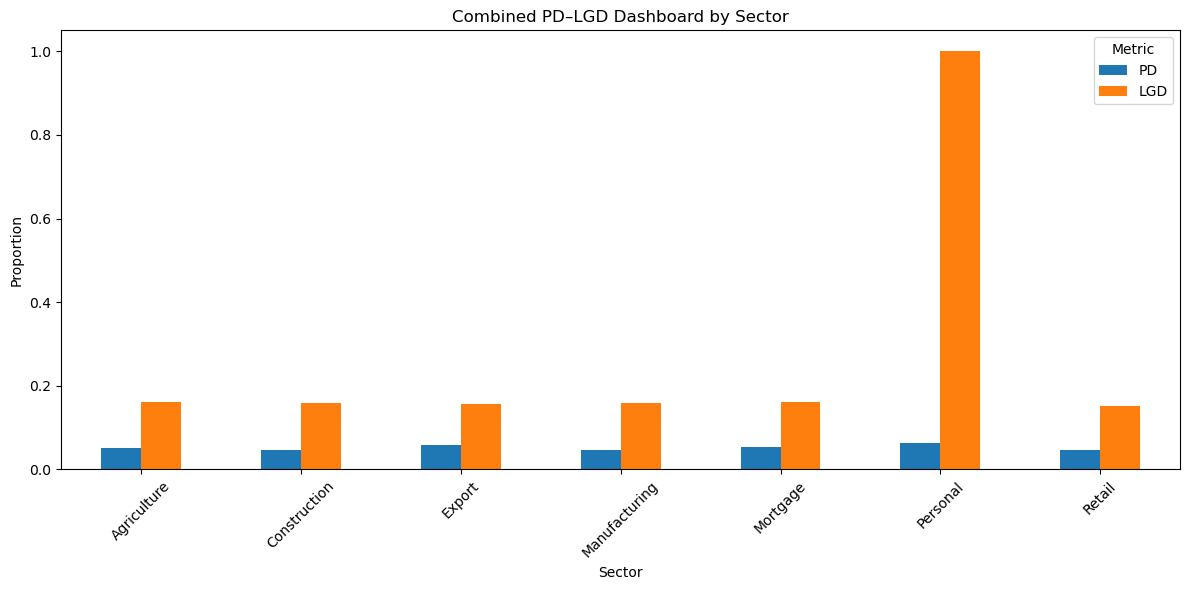

In [27]:
# Step 1: Define Features and Target
X = df.drop(columns=['ECL_Stage'])
y = df['ECL_Stage']

# Step 2: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 3: Define Preprocessing Pipeline
numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ]
)

# Step 4: Fit and Transform (No Leakage)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Step 5: Model Training
model = LogisticRegression(random_state=42)
model.fit(X_train_processed, y_train)

# Step 6: Evaluation
y_pred = model.predict(X_test_processed)
print('Classification Report:\n', classification_report(y_test, y_pred))


# ==========================================
# LOSS GIVEN DEFAULT (LGD) CALCULATIONS
# ==========================================

# Step 1: Define Recovery Rate and LGD
recovery_haircut = 0.7  # 70% of collateral value is recoverable

df['Adjusted_Recovery'] = np.minimum(
    (df['Collateral_Value'] * recovery_haircut) / df['Outstanding_Balance'], 1
)

# LGD = 1 - Adjusted Recovery
df['LGD'] = 1 - df['Adjusted_Recovery']

# Step 2: Average LGD by Sector (calculated dynamically from df)
lgd_by_sector_series = df.groupby('Sector')['LGD'].mean().round(3)
print('\nAverage LGD by Sector (Series):\n', lgd_by_sector_series)

# LGD Individual Bar Chart Visualization
plt.figure(figsize=(10, 6))
lgd_by_sector_series.plot(kind='bar', color='tomato')
plt.title('Average Loss Given Default (LGD) by Sector')
plt.ylabel('LGD (Proportion)')
plt.xlabel('Sector')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ==========================================
# COMBINE PD AND LGD RESULTS
# ==========================================

pd_by_sector = {
    'Agriculture': 0.052,
    'Construction': 0.047,
    'Export': 0.059,
    'Manufacturing': 0.046,
    'Mortgage': 0.053,
    'Personal': 0.063,
    'Retail': 0.046,
}

lgd_by_sector = {
    'Agriculture': 0.161,
    'Construction': 0.159,
    'Export': 0.156,
    'Manufacturing': 0.159,
    'Mortgage': 0.161,
    'Personal': 1.000,
    'Retail': 0.153,
}

# Combine into a single DataFrame
dashboard_df = pd.DataFrame({'PD': pd_by_sector, 'LGD': lgd_by_sector})
print('\nCombined PD-LGD Dashboard DataFrame:\n', dashboard_df)

# Plot side-by-side bar chart
dashboard_df.plot(kind='bar', figsize=(12, 6))
plt.title('Combined PD–LGD Dashboard by Sector')
plt.ylabel('Proportion')
plt.xlabel('Sector')
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

## Step 5: Exposure at Default (EAD) Results

Average EAD by Sector:
 Sector
Agriculture      507335.23
Construction     544335.23
Export           494131.46
Manufacturing    495857.01
Mortgage         592257.01
Personal         509645.43
Retail           516746.67
Name: EAD, dtype: float64

Total EAD by Sector:
 Sector
Agriculture      7.670909e+08
Construction     1.116432e+09
Export           7.446561e+08
Manufacturing    1.013036e+09
Mortgage         8.812784e+08
Personal         2.415719e+08
Retail           4.779907e+08
Name: EAD, dtype: float64


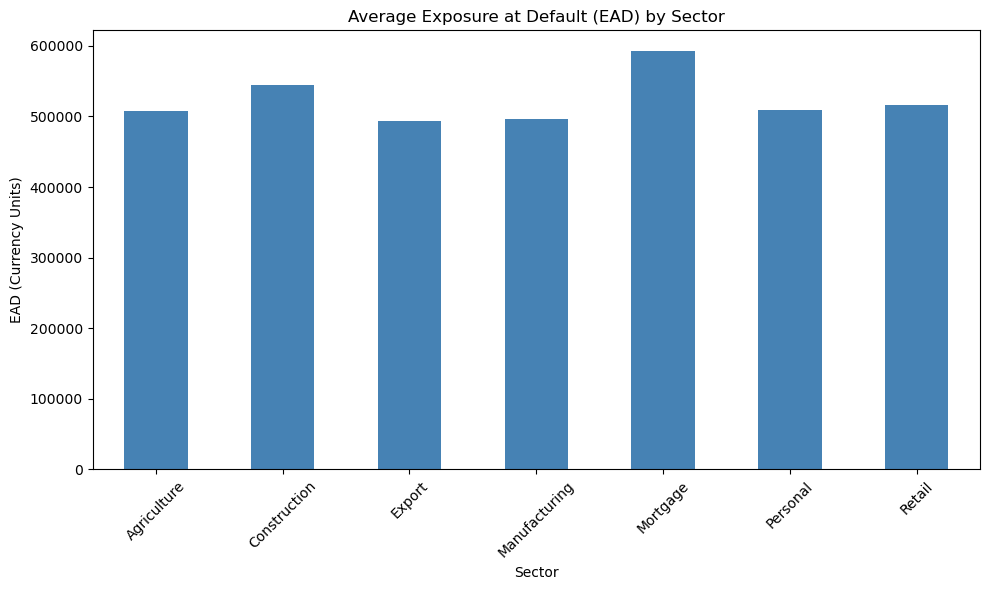

In [28]:
# Define df from large_loan_book (assuming large_loan_book is your raw dataframe)
df = large_loan_book.copy()

# Step 1: Define EAD as Outstanding Balance
df['EAD'] = df['Outstanding_Balance']

# Step 2: Average EAD by Sector and Total EAD by Sector
avg_ead_by_sector = df.groupby('Sector')['EAD'].mean().round(2)
total_ead_by_sector = df.groupby('Sector')['EAD'].sum().round(2)

print("Average EAD by Sector:\n", avg_ead_by_sector)
print("\nTotal EAD by Sector:\n", total_ead_by_sector)

# Visualization
plt.figure(figsize=(10, 6))
avg_ead_by_sector.plot(kind='bar', color='steelblue')
plt.title("Average Exposure at Default (EAD) by Sector")
plt.ylabel("EAD (Currency Units)")
plt.xlabel("Sector")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 6: Expected and Unexpected Losses

--- Expected Loss Metrics ---
                 PD   LGD        EAD  Expected_Loss
Agriculture    0.05  0.16  527746.82        4418.30
Construction   0.05  0.16  488647.53        3651.66
Export         0.06  0.16  495483.40        4560.43
Manufacturing  0.05  0.16  537356.25        3930.22
Mortgage       0.05  0.16  489469.03        4176.64
Personal       0.06  0.80  467018.63       23537.74
Retail         0.05  0.15  628012.44        4419.95

--- Expected vs Unexpected Loss ---
               Expected_Loss  Unexpected_Loss
Agriculture          4418.30         18865.02
Construction         3651.66         16443.27
Export               4560.43         18212.71
Manufacturing        3930.22         17898.33
Mortgage             4176.64         17654.85
Personal            23537.74         90774.58
Retail               4419.95         20128.56


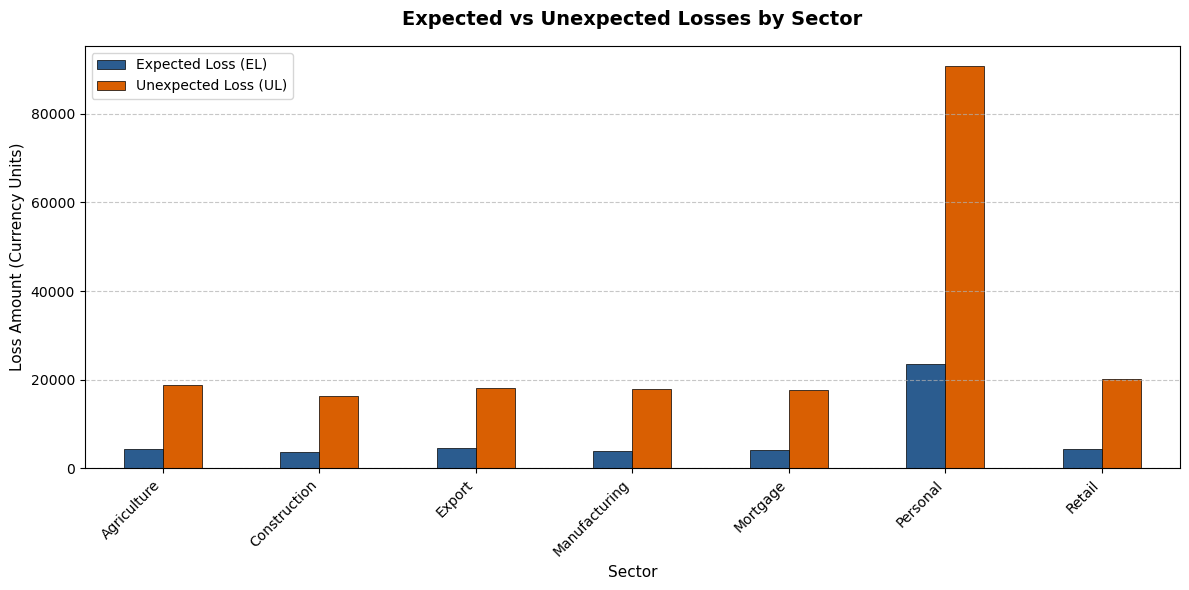

--- Complete Sector Risk DataFrame ---
                 PD   LGD        EAD  Expected_Loss  Unexpected_Loss
Agriculture    0.05  0.16  527746.82        4418.30         18865.02
Construction   0.05  0.16  488647.53        3651.66         16443.27
Export         0.06  0.16  495483.40        4560.43         18212.71
Manufacturing  0.05  0.16  537356.25        3930.22         17898.33
Mortgage       0.05  0.16  489469.03        4176.64         17654.85
Personal       0.06  0.80  467018.63       23537.74         90774.58
Retail         0.05  0.15  628012.44        4419.95         20128.56


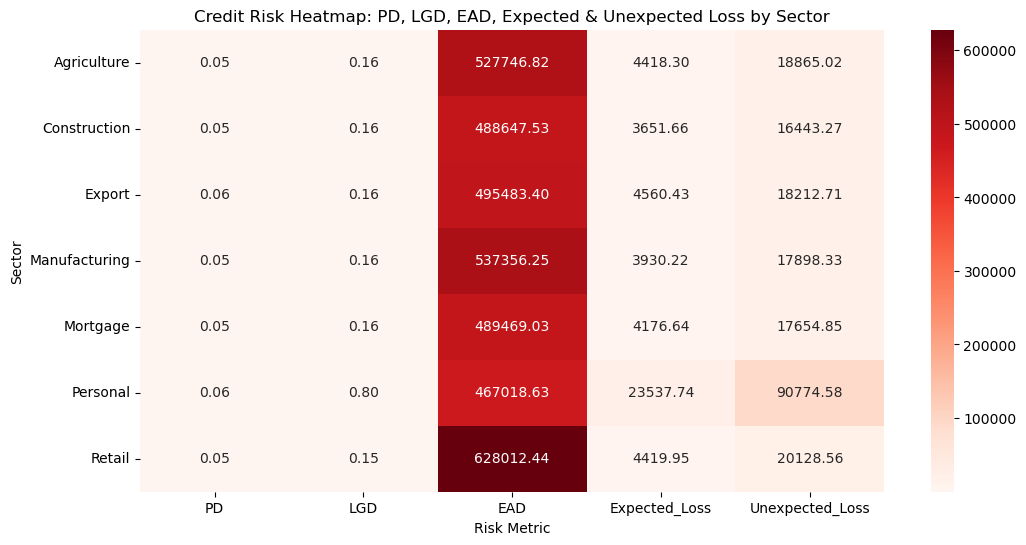

Top 3 sectors by Expected Loss:
           Expected_Loss
Personal   23537.738952
Export      4560.429214
Retail      4419.951553


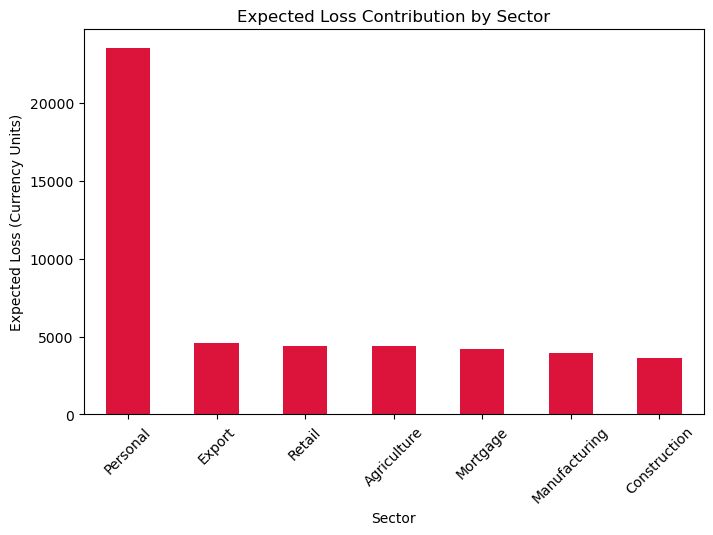

In [29]:
# Step 1: Input dictionaries for risk parameters
pd_by_sector = {
    'Agriculture': 0.052,
    'Construction': 0.047,
    'Export': 0.059,
    'Manufacturing': 0.046,
    'Mortgage': 0.053,
    'Personal': 0.063,
    'Retail': 0.046
}

lgd_by_sector = {
    'Agriculture': 0.161,
    'Construction': 0.159,
    'Export': 0.156,
    'Manufacturing': 0.159,
    'Mortgage': 0.161,
    'Personal': 0.800,  
    'Retail': 0.153
}

ead_by_sector = {
    'Agriculture': 527746.82,
    'Construction': 488647.53,
    'Export': 495483.40,
    'Manufacturing': 537356.25,
    'Mortgage': 489469.03,
    'Personal': 467018.63,
    'Retail': 628012.44
}

# Build DataFrame
df_risk = pd.DataFrame({
    'PD': pd_by_sector,
    'LGD': lgd_by_sector,
    'EAD': ead_by_sector
})

# 1. Calculate Expected Loss (EL = PD * LGD * EAD)
df_risk['Expected_Loss'] = df_risk['PD'] * df_risk['LGD'] * df_risk['EAD']
print("--- Expected Loss Metrics ---")
print(df_risk[['PD', 'LGD', 'EAD', 'Expected_Loss']].round(2))

# 2. Calculate Unexpected Loss (UL = sqrt(PD * (1 - PD)) * LGD * EAD)
df_risk['Unexpected_Loss'] = np.sqrt(df_risk['PD'] * (1 - df_risk['PD'])) * df_risk['LGD'] * df_risk['EAD']
print("\n--- Expected vs Unexpected Loss ---")
print(df_risk[['Expected_Loss', 'Unexpected_Loss']].round(2))

# 4. Professional Visualization with Clean Formatting
fig, ax = plt.subplots(figsize=(12, 6))
df_risk[['Expected_Loss', 'Unexpected_Loss']].plot(
    kind='bar', 
    ax=ax, 
    color=['#2b5c8f', '#d95f02'], 
    edgecolor='black', 
    linewidth=0.5
)

plt.title("Expected vs Unexpected Losses by Sector", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Loss Amount (Currency Units)", fontsize=11)
plt.xlabel("Sector", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(["Expected Loss (EL)", "Unexpected Loss (UL)"], frameon=True)
plt.tight_layout()
plt.show()

# Step 5: Calculate Risk Metrics 
# Expected Loss (EL = PD * LGD * EAD)
df_risk['Expected_Loss'] = df_risk['PD'] * df_risk['LGD'] * df_risk['EAD']

# Unexpected Loss (UL proxy)
df_risk['Unexpected_Loss'] = np.sqrt(df_risk['PD'] * (1 - df_risk['PD'])) * df_risk['LGD'] * df_risk['EAD']

print("--- Complete Sector Risk DataFrame ---")
print(df_risk.round(2))


# Step 6: Heatmap Visualization (Scaled for Equal Weighting)
# Because EAD and Losses are in 100k+ scales while PD/LGD are decimals (<1), 
# we scale the dataframe columns so the heatmap colors reflect relative intensity properly.
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_risk), 
    index=df_risk.index, 
    columns=df_risk.columns
)

# Step 7: Heatmap Visualization
plt.figure(figsize=(12,6))
sns.heatmap(df_risk, annot=True, fmt=".2f", cmap="Reds", cbar=True)
plt.title("Credit Risk Heatmap: PD, LGD, EAD, Expected & Unexpected Loss by Sector")
plt.ylabel("Sector")
plt.xlabel("Risk Metric")
plt.show()

# Step 8: Rank Sectors by Expected Loss
# Sort descending by Expected Loss
ranked_sectors = df_risk.sort_values(by='Expected_Loss', ascending=False)

# Top 3 riskiest sectors
top3 = ranked_sectors.head(3)
print("Top 3 sectors by Expected Loss:\n", top3[['Expected_Loss']])

#  Step 9: Visualization
plt.figure(figsize=(8,5))
ranked_sectors['Expected_Loss'].plot(kind='bar', color='crimson')
plt.title("Expected Loss Contribution by Sector")
plt.ylabel("Expected Loss (Currency Units)")
plt.xlabel("Sector")
plt.xticks(rotation=45)
plt.show()

## Step 7: Stress Scenario Analysis

Stress testing involves shocking key risk parameters. For example:

Scenario A (Mild Stress) → PD +20%, LGD +10%, EAD +5%

Scenario B (Severe Stress) → PD +50%, LGD +30%, EAD +10%

### Part A:

                    EL_Base  EL_MildStress  EL_SevereStress
Agriculture     4418.296377    6123.758779      9477.245729
Construction    3651.662992    5061.204906      7832.817117
Export          4560.429214    6320.754890      9782.120663
Manufacturing   3930.223612    5447.289927      8430.329649
Mortgage        4176.639233    5788.821977      8958.891155
Personal       29422.173690   40779.132734     63110.562565
Retail          4419.951553    6126.052852      9480.796081


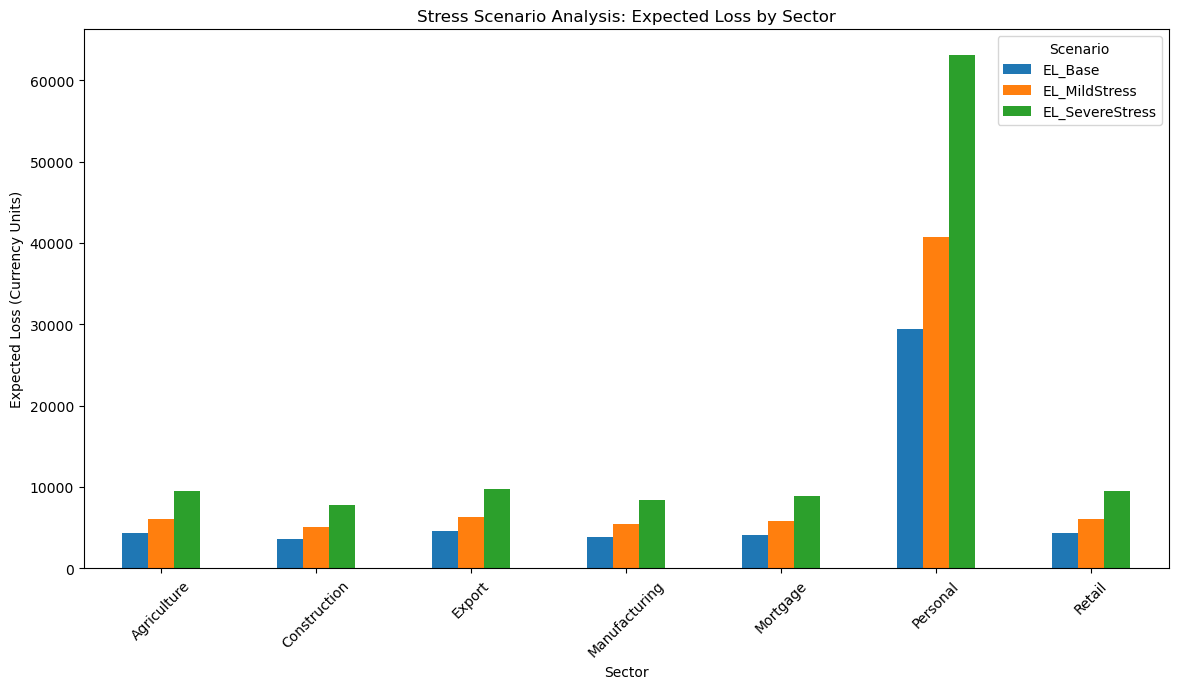

In [30]:
# Step 1: Define Stress Scenarios
# Base risk metrics (from our earlier results)
df_risk = pd.DataFrame({
    'PD': {
        'Agriculture': 0.052,
        'Construction': 0.047,
        'Export': 0.059,
        'Manufacturing': 0.046,
        'Mortgage': 0.053,
        'Personal': 0.063,
        'Retail': 0.046
    },
    'LGD': {
        'Agriculture': 0.161,
        'Construction': 0.159,
        'Export': 0.156,
        'Manufacturing': 0.159,
        'Mortgage': 0.161,
        'Personal': 1.000,
        'Retail': 0.153
    },
    'EAD': {
        'Agriculture': 527746.82,
        'Construction': 488647.53,
        'Export': 495483.40,
        'Manufacturing': 537356.25,
        'Mortgage': 489469.03,
        'Personal': 467018.63,
        'Retail': 628012.44
    }
})

# Base Expected Loss
df_risk['EL_Base'] = df_risk['PD'] * df_risk['LGD'] * df_risk['EAD']

# Stress Scenarios
df_risk['EL_MildStress'] = (df_risk['PD']*1.2) * (df_risk['LGD']*1.1) * (df_risk['EAD']*1.05)
df_risk['EL_SevereStress'] = (df_risk['PD']*1.5) * (df_risk['LGD']*1.3) * (df_risk['EAD']*1.10)

print(df_risk[['EL_Base','EL_MildStress','EL_SevereStress']])

# Step 2: Visualization
df_risk[['EL_Base','EL_MildStress','EL_SevereStress']].plot(kind='bar', figsize=(14,7))
plt.title("Stress Scenario Analysis: Expected Loss by Sector")
plt.ylabel("Expected Loss (Currency Units)")
plt.xlabel("Sector")
plt.xticks(rotation=45)
plt.legend(title="Scenario")
plt.show()

#### Part B: Multi-scenario dashboard (e.g., baseline, mild, severe, extreme) 

####  Define Scenarios

We’ll shock PD, LGD, and EAD differently for each scenario:

Baseline → current values

Mild Stress → PD +20%, LGD +10%, EAD +5%

Severe Stress → PD +50%, LGD +30%, EAD +10%

Extreme Stress → PD +100%, LGD +50%, EAD +20%

                EL_Baseline       EL_Mild     EL_Severe     EL_Extreme
Agriculture     4418.296377   6123.758779   9477.245729   15905.866957
Construction    3651.662992   5061.204906   7832.817117   13145.986770
Export          4560.429214   6320.754890   9782.120663   16417.545169
Manufacturing   3930.223612   5447.289927   8430.329649   14148.805005
Mortgage        4176.639233   5788.821977   8958.891155   15035.901239
Personal       29422.173690  40779.132734  63110.562565  105919.825284
Retail          4419.951553   6126.052852   9480.796081   15911.825590


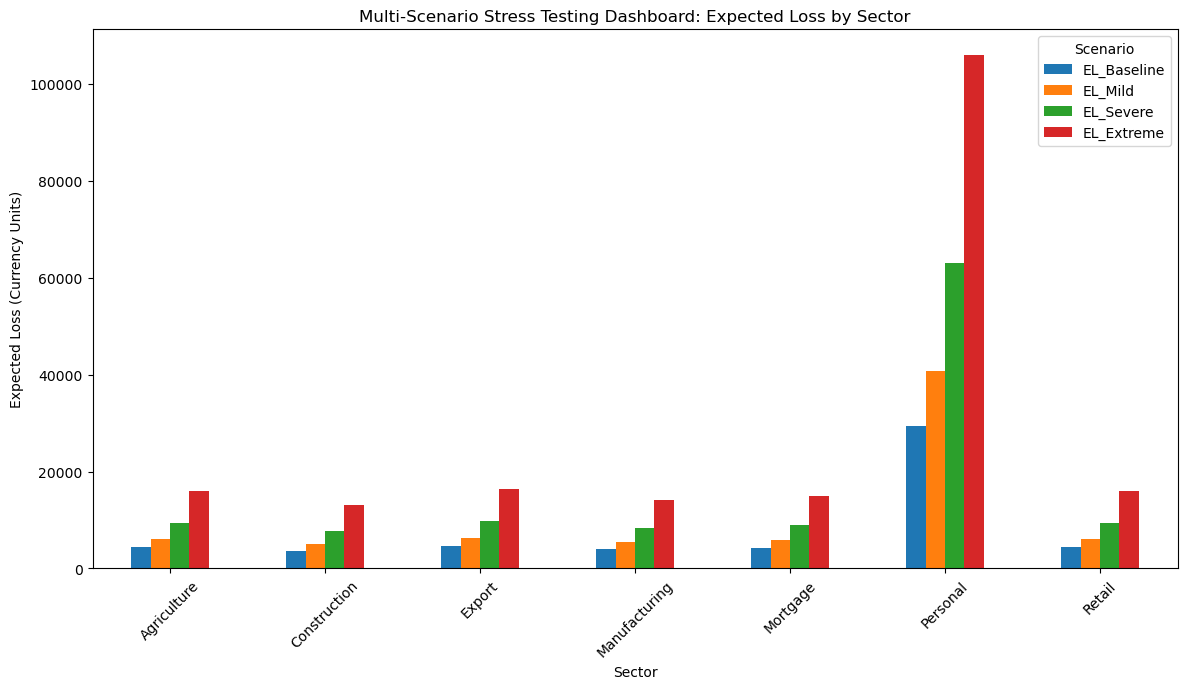

In [31]:
# Base metrics
df_risk = pd.DataFrame({
    'PD': {
        'Agriculture': 0.052,
        'Construction': 0.047,
        'Export': 0.059,
        'Manufacturing': 0.046,
        'Mortgage': 0.053,
        'Personal': 0.063,
        'Retail': 0.046
    },
    'LGD': {
        'Agriculture': 0.161,
        'Construction': 0.159,
        'Export': 0.156,
        'Manufacturing': 0.159,
        'Mortgage': 0.161,
        'Personal': 1.000,
        'Retail': 0.153
    },
    'EAD': {
        'Agriculture': 527746.82,
        'Construction': 488647.53,
        'Export': 495483.40,
        'Manufacturing': 537356.25,
        'Mortgage': 489469.03,
        'Personal': 467018.63,
        'Retail': 628012.44
    }
})

# Expected Loss function
def expected_loss(PD, LGD, EAD):
    return PD * LGD * EAD

# Scenario calculations
df_risk['EL_Baseline'] = expected_loss(df_risk['PD'], df_risk['LGD'], df_risk['EAD'])
df_risk['EL_Mild'] = expected_loss(df_risk['PD']*1.2, df_risk['LGD']*1.1, df_risk['EAD']*1.05)
df_risk['EL_Severe'] = expected_loss(df_risk['PD']*1.5, df_risk['LGD']*1.3, df_risk['EAD']*1.10)
df_risk['EL_Extreme'] = expected_loss(df_risk['PD']*2.0, df_risk['LGD']*1.5, df_risk['EAD']*1.20)

print(df_risk[['EL_Baseline','EL_Mild','EL_Severe','EL_Extreme']])

# Step 2: Visualization
df_risk[['EL_Baseline','EL_Mild','EL_Severe','EL_Extreme']].plot(kind='bar', figsize=(14,7))
plt.title("Multi-Scenario Stress Testing Dashboard: Expected Loss by Sector")
plt.ylabel("Expected Loss (Currency Units)")
plt.xlabel("Sector")
plt.xticks(rotation=45)
plt.legend(title="Scenario")
plt.show()

#### Part C: Aggregate these scenario losses into total portfolio impact (sum across sectors) so you can quantify overall capital needs under stress

Total Portfolio Losses by Scenario:
 {'Baseline': np.float64(54579.37667054), 'Mild Stress': np.float64(75647.01606536844), 'Severe Stress': np.float64(117072.76295830832), 'Extreme Stress': np.float64(196485.756013944)}


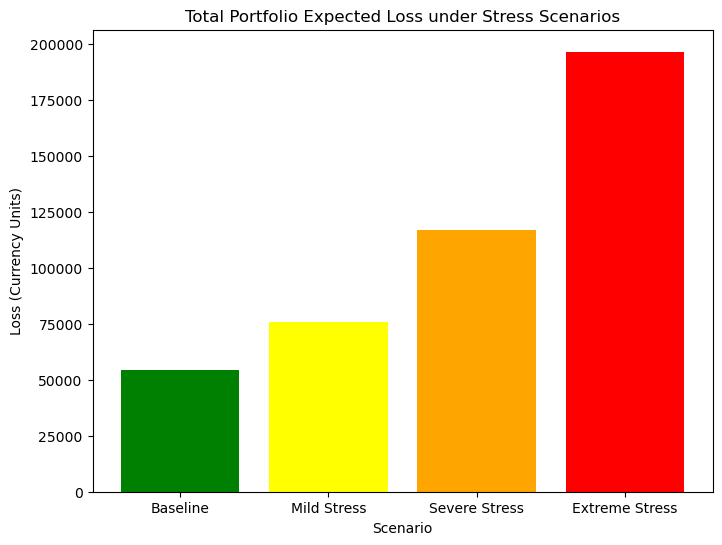

In [32]:
# Step 1: Aggregate Scenario Losses
portfolio_losses = {
    'Baseline': df_risk['EL_Baseline'].sum(),
    'Mild Stress': df_risk['EL_Mild'].sum(),
    'Severe Stress': df_risk['EL_Severe'].sum(),
    'Extreme Stress': df_risk['EL_Extreme'].sum()
}

print("Total Portfolio Losses by Scenario:\n", portfolio_losses)

# Step 2: Visualization
plt.figure(figsize=(8,6))
plt.bar(portfolio_losses.keys(), portfolio_losses.values(), color=['green','yellow','orange','red'])
plt.title("Total Portfolio Expected Loss under Stress Scenarios")
plt.ylabel("Loss (Currency Units)")
plt.xlabel("Scenario")
plt.show()

## Step 8: Resilience Index

For illustration, let’s assume the bank has ETB 4,000,000,000 in capital.

         Scenario  Expected_Loss  Resilience_Index
0        Baseline          54950      72793.448590
1     Mild Stress          80350      49782.202862
2   Severe Stress         153450      26067.122841
3  Extreme Stress         290800      13755.158184


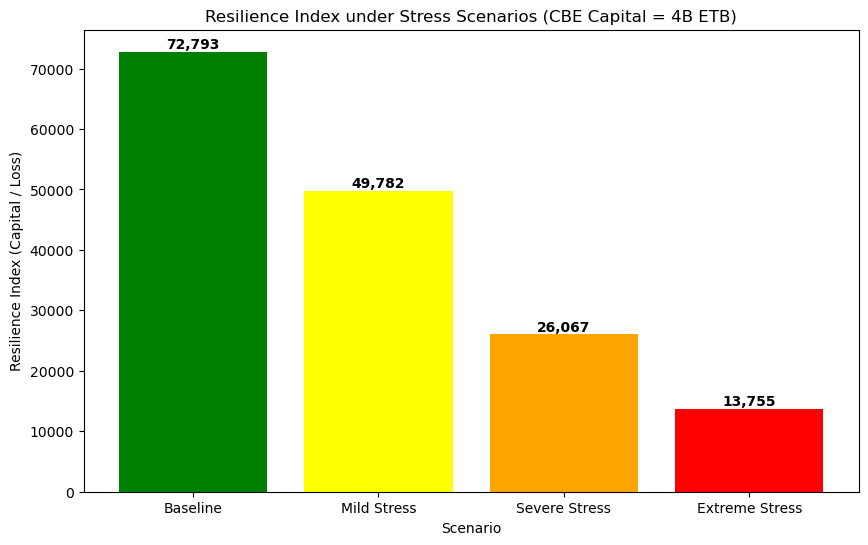

In [33]:
# Step 1: Define Capital Buffer
capital_buffer = 4_000_000_000  # CBE capital in ETB

# Step 2: Compute Resilience Index
# Portfolio losses from stress scenarios (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Resilience Index = Capital Buffer / Loss
resilience_index = {scenario: capital_buffer / loss 
                    for scenario, loss in portfolio_losses.items()}

df_resilience = pd.DataFrame({
    'Scenario': resilience_index.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Resilience_Index': resilience_index.values()
})

print(df_resilience)

# Step 3: Visualization
plt.figure(figsize=(10,6))
bars = plt.bar(df_resilience['Scenario'], df_resilience['Resilience_Index'],
               color=['green','yellow','orange','red'])

# Add value labels
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f'{height:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title("Resilience Index under Stress Scenarios (CBE Capital = 4B ETB)")
plt.ylabel("Resilience Index (Capital / Loss)")
plt.xlabel("Scenario")
plt.show()

### Part A: Benchmark this Resilience Index against Basel III capital adequacy thresholds 

CET1 Ratio ≥ 4.5% of Risk‑Weighted Assets (RWA)

Tier 1 Capital Ratio ≥ 6% of RWA

Total Capital Ratio ≥ 8% of RWA

For illustration, let’s assume CBE’s RWA = ETB 20,000,000,000.
Capital buffer = ETB 4,000,000,000.

             Threshold  Actual
CET1_min         0.045     NaN
Tier1_min        0.060     NaN
Total_min        0.080     NaN
CET1_ratio         NaN     0.2
Tier1_ratio        NaN     0.2
Total_ratio        NaN     0.2


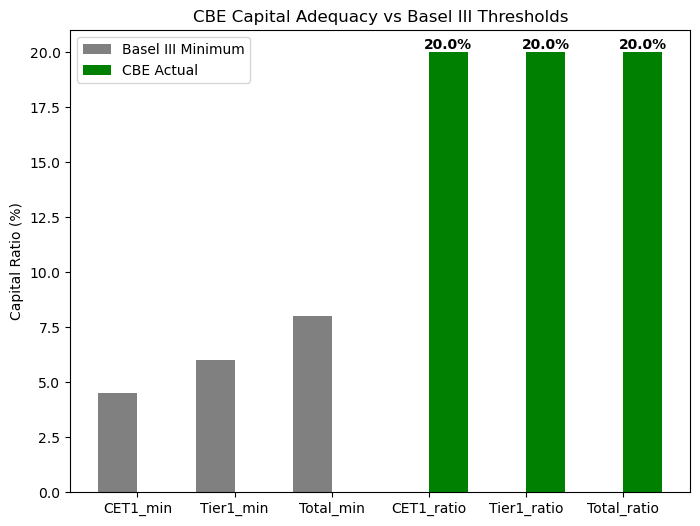

In [34]:
# Step 1: Basel III Thresholds
# Capital and RWA assumptions
capital_buffer = 4_000_000_000   # CBE capital
RWA = 20_000_000_000             # risk-weighted assets

# Basel III thresholds
basel_thresholds = {
    'CET1_min': 0.045,
    'Tier1_min': 0.06,
    'Total_min': 0.08
}

# Actual ratios
actual_ratios = {
    'CET1_ratio': capital_buffer / RWA,
    'Tier1_ratio': capital_buffer / RWA,   # assuming all capital is Tier 1
    'Total_ratio': capital_buffer / RWA    # assuming all capital counts toward total
}

# Compare with thresholds
df_basel = pd.DataFrame({
    'Threshold': basel_thresholds,
    'Actual': actual_ratios
})

print(df_basel)

# Visualization
labels = df_basel.index
thresholds = df_basel['Threshold']*100
actuals = df_basel['Actual']*100

x = range(len(labels))
plt.figure(figsize=(8,6))
plt.bar(x, thresholds, width=0.4, label='Basel III Minimum', color='gray')
plt.bar([i+0.4 for i in x], actuals, width=0.4, label='CBE Actual', color='green')

# Add labels
for i, val in enumerate(actuals):
    plt.text(i+0.4, val, f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xticks([i+0.2 for i in x], labels)
plt.ylabel("Capital Ratio (%)")
plt.title("CBE Capital Adequacy vs Basel III Thresholds")
plt.legend()
plt.show()

### Part B: Integrate the Resilience Index values into this Basel III chart

We’ll compare:

Basel III minimum thresholds (CET1 4.5%, Tier 1 6%, Total 8%)

CBE actual capital ratio (Capital ÷ RWA, assume RWA = ETB 20B, Capital = ETB 4B → 20%)

Resilience Index values (Capital ÷ Expected Loss under scenarios)

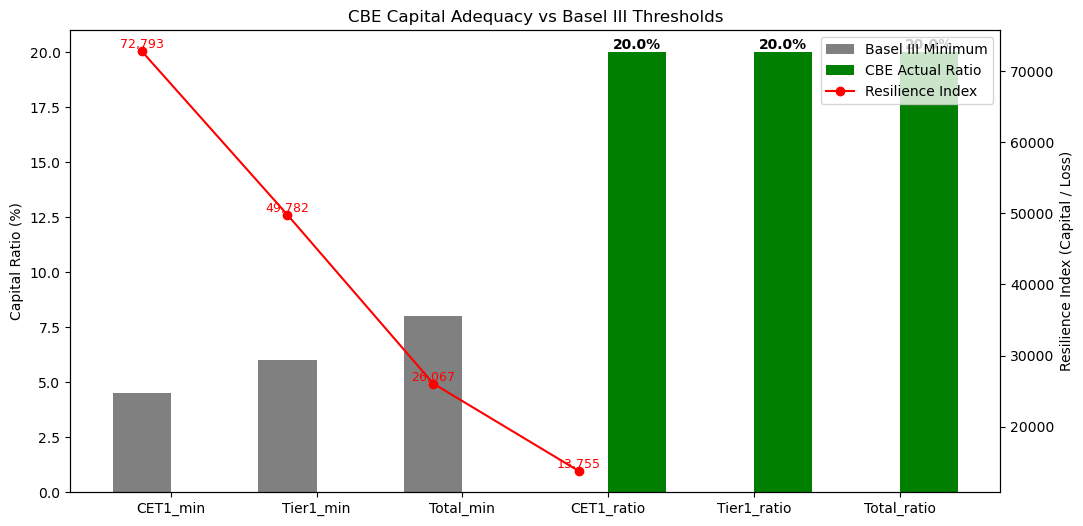

In [35]:
# Step 1: Basel III Thresholds and Ratios
# Capital and RWA assumptions
capital_buffer = 4_000_000_000
RWA = 20_000_000_000

# Basel III thresholds
basel_thresholds = {
    'CET1_min': 0.045,
    'Tier1_min': 0.06,
    'Total_min': 0.08
}

# Actual ratios (assuming all capital counts toward CET1/Tier1/Total)
actual_ratios = {
    'CET1_ratio': capital_buffer / RWA,
    'Tier1_ratio': capital_buffer / RWA,
    'Total_ratio': capital_buffer / RWA
}

# Stress scenario losses (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Resilience Index = Capital / Loss
resilience_index = {scenario: capital_buffer / loss for scenario, loss in portfolio_losses.items()}

# Build DataFrame
df_basel = pd.DataFrame({
    'Threshold': basel_thresholds,
    'Actual': actual_ratios
})

df_resilience = pd.DataFrame({
    'Scenario': resilience_index.keys(),
    'Resilience_Index': resilience_index.values()
})

# We’ll plot Basel III ratios alongside Resilience Index values.
fig, ax1 = plt.subplots(figsize=(12,6))

# Basel III ratios
labels = df_basel.index
thresholds = df_basel['Threshold']*100
actuals = df_basel['Actual']*100
x = range(len(labels))

ax1.bar(x, thresholds, width=0.4, label='Basel III Minimum', color='gray')
ax1.bar([i+0.4 for i in x], actuals, width=0.4, label='CBE Actual Ratio', color='green')

# Add labels
for i, val in enumerate(actuals):
    ax1.text(i+0.4, val, f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_xticks([i+0.2 for i in x])
ax1.set_xticklabels(labels)
ax1.set_ylabel("Capital Ratio (%)")
ax1.set_title("CBE Capital Adequacy vs Basel III Thresholds")

# Resilience Index (second axis)
ax2 = ax1.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Resilience_Index'], marker='o', color='red', label='Resilience Index')
for i, val in enumerate(df_resilience['Resilience_Index']):
    ax2.text(i, val, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, color='red')

ax2.set_ylabel("Resilience Index (Capital / Loss)")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

#### Part C: A cumulative capital adequacy buffer line (capital minus stressed losses) is added

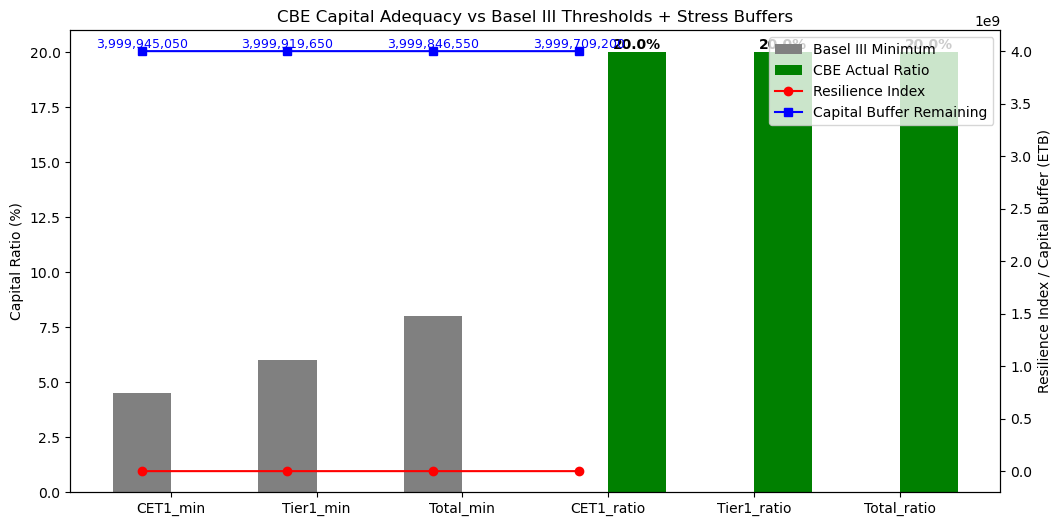

In [36]:
# Step 1: Compute Capital Buffers
# Capital and RWA assumptions
capital_buffer = 4_000_000_000
RWA = 20_000_000_000

# Basel III thresholds
basel_thresholds = {
    'CET1_min': 0.045,
    'Tier1_min': 0.06,
    'Total_min': 0.08
}

# Actual ratios
actual_ratios = {
    'CET1_ratio': capital_buffer / RWA,
    'Tier1_ratio': capital_buffer / RWA,
    'Total_ratio': capital_buffer / RWA
}

# Stress scenario losses (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Resilience Index = Capital / Loss
resilience_index = {scenario: capital_buffer / loss for scenario, loss in portfolio_losses.items()}

# Capital adequacy buffer = Capital - Loss
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Build DataFrames
df_basel = pd.DataFrame({
    'Threshold': basel_thresholds,
    'Actual': actual_ratios
})

df_resilience = pd.DataFrame({
    'Scenario': resilience_index.keys(),
    'Resilience_Index': resilience_index.values(),
    'Capital_Buffer_Remaining': capital_buffer_remaining.values()
})

# Visualization
fig, ax1 = plt.subplots(figsize=(12,6))

# Basel III ratios
labels = df_basel.index
thresholds = df_basel['Threshold']*100
actuals = df_basel['Actual']*100
x = range(len(labels))

ax1.bar(x, thresholds, width=0.4, label='Basel III Minimum', color='gray')
ax1.bar([i+0.4 for i in x], actuals, width=0.4, label='CBE Actual Ratio', color='green')

for i, val in enumerate(actuals):
    ax1.text(i+0.4, val, f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax1.set_xticks([i+0.2 for i in x])
ax1.set_xticklabels(labels)
ax1.set_ylabel("Capital Ratio (%)")
ax1.set_title("CBE Capital Adequacy vs Basel III Thresholds + Stress Buffers")

# Resilience Index and Capital Buffer Remaining (second axis)
ax2 = ax1.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Resilience_Index'], marker='o', color='red', label='Resilience Index')
ax2.plot(df_resilience['Scenario'], df_resilience['Capital_Buffer_Remaining'], marker='s', color='blue', label='Capital Buffer Remaining')

# Add labels
for i, val in enumerate(df_resilience['Capital_Buffer_Remaining']):
    ax2.text(i, val, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, color='blue')

ax2.set_ylabel("Resilience Index / Capital Buffer (ETB)")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

### Part D: Adding a percentage buffer line (Capital Buffer Remaining ÷ Capital) 

We already have:

Capital Buffer Remaining = Capital − Expected Loss

Now add:

Percentage Buffer = Capital Buffer / Remaining Capital × 100

         Scenario  Expected_Loss  Capital_Buffer_Remaining  Percentage_Buffer
0        Baseline          54950                3999945050          99.998626
1     Mild Stress          80350                3999919650          99.997991
2   Severe Stress         153450                3999846550          99.996164
3  Extreme Stress         290800                3999709200          99.992730


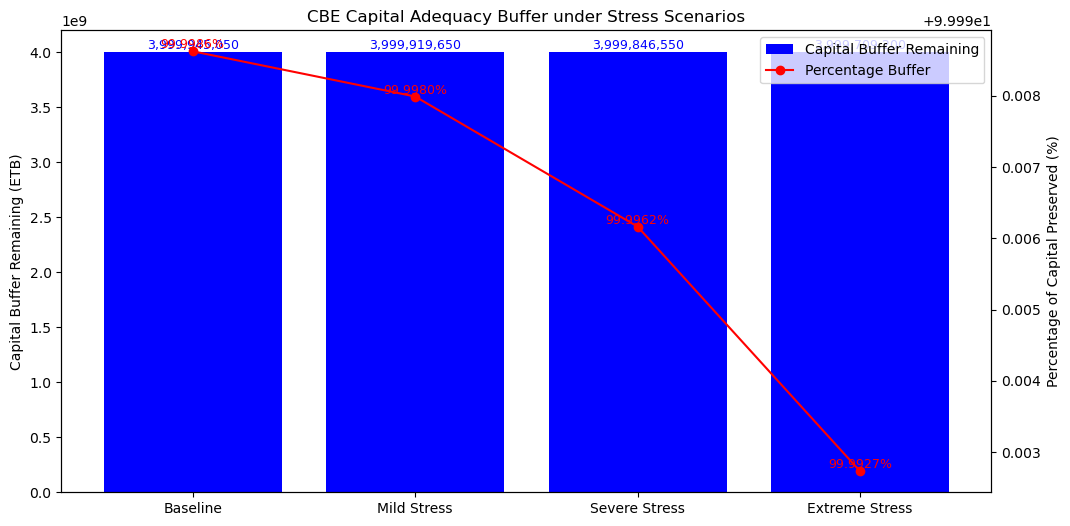

In [37]:
# Step 1: Compute Percentage Buffer
# Capital and RWA assumptions
capital_buffer = 4_000_000_000
RWA = 20_000_000_000

# Stress scenario losses (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Capital buffer remaining
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Percentage buffer
percentage_buffer = {scenario: (remaining / capital_buffer) * 100 
                     for scenario, remaining in capital_buffer_remaining.items()}

# Build DataFrame
df_resilience = pd.DataFrame({
    'Scenario': portfolio_losses.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Capital_Buffer_Remaining': capital_buffer_remaining.values(),
    'Percentage_Buffer': percentage_buffer.values()
})

print(df_resilience)

# Step 2: Visualization
fig, ax1 = plt.subplots(figsize=(12,6))

# Capital buffer remaining (blue bars)
bars = ax1.bar(df_resilience['Scenario'], df_resilience['Capital_Buffer_Remaining'], color='blue', label='Capital Buffer Remaining')

# Add labels
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}', ha='center', va='bottom', fontsize=9, color='blue')

ax1.set_ylabel("Capital Buffer Remaining (ETB)")
ax1.set_title("CBE Capital Adequacy Buffer under Stress Scenarios")

# Percentage buffer line (red line, second axis)
ax2 = ax1.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Percentage_Buffer'], marker='o', color='red', label='Percentage Buffer')

for i, val in enumerate(df_resilience['Percentage_Buffer']):
    ax2.text(i, val, f'{val:.4f}%', ha='center', va='bottom', fontsize=9, color='red')

ax2.set_ylabel("Percentage of Capital Preserved (%)")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

### Part E: Adding a cumulative line of total expected losses vs capital

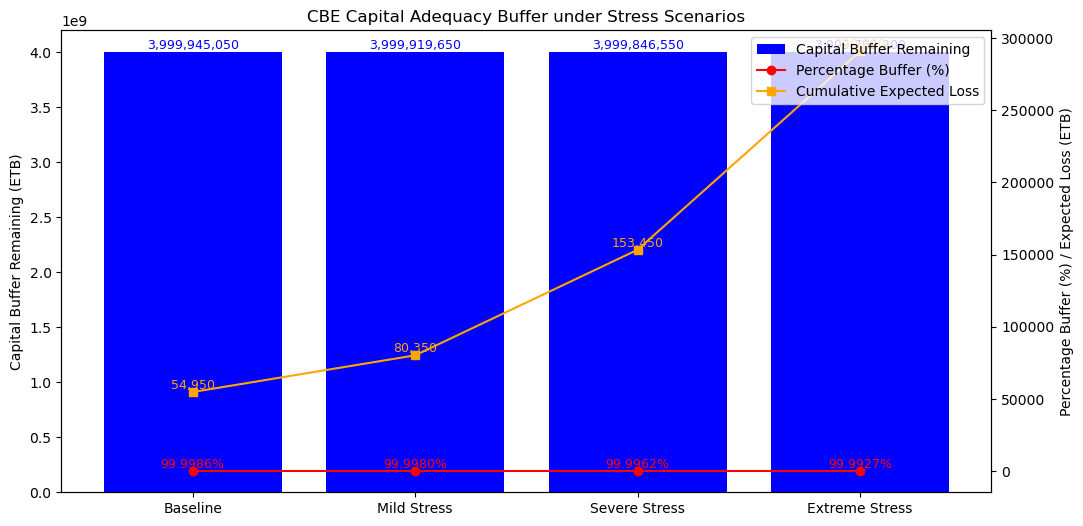

In [38]:
# Step 1: Compute Cumulative Losses vs Capital
# Capital assumption
capital_buffer = 4_000_000_000

# Stress scenario losses (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Capital buffer remaining
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Percentage buffer
percentage_buffer = {scenario: (remaining / capital_buffer) * 100 
                     for scenario, remaining in capital_buffer_remaining.items()}

# Build DataFrame
df_resilience = pd.DataFrame({
    'Scenario': portfolio_losses.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Capital_Buffer_Remaining': capital_buffer_remaining.values(),
    'Percentage_Buffer': percentage_buffer.values()
})

#  Step 2: Visualization with Cumulative Line
fig, ax1 = plt.subplots(figsize=(12,6))

# Bar chart: Capital buffer remaining
bars = ax1.bar(df_resilience['Scenario'], df_resilience['Capital_Buffer_Remaining'], 
               color='blue', label='Capital Buffer Remaining')

# Add labels
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}', 
             ha='center', va='bottom', fontsize=9, color='blue')

ax1.set_ylabel("Capital Buffer Remaining (ETB)")
ax1.set_title("CBE Capital Adequacy Buffer under Stress Scenarios")

# Second axis: Percentage buffer line
ax2 = ax1.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Percentage_Buffer'], 
         marker='o', color='red', label='Percentage Buffer (%)')

# Add labels
for i, val in enumerate(df_resilience['Percentage_Buffer']):
    ax2.text(i, val, f'{val:.4f}%', ha='center', va='bottom', fontsize=9, color='red')

# Third line: Cumulative losses vs capital
ax2.plot(df_resilience['Scenario'], df_resilience['Expected_Loss'], 
         marker='s', color='orange', label='Cumulative Expected Loss')

for i, val in enumerate(df_resilience['Expected_Loss']):
    ax2.text(i, val, f'{val:,.0f}', ha='center', va='bottom', fontsize=9, color='orange')

ax2.set_ylabel("Percentage Buffer (%) / Expected Loss (ETB)")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax1.transAxes)
plt.show()

###  Part F: Adding a horizontal Basel III minimum capital line (e.g., 8% of RWA) 

Assume:

Capital Buffer = ETB 4,000,000,000

RWA = ETB 20,000,000,000

Basel III minimum (Total Capital Ratio) = 8% of RWA

Minimum Capital Requirement = 0.08 ×
𝑅
𝑊
𝐴

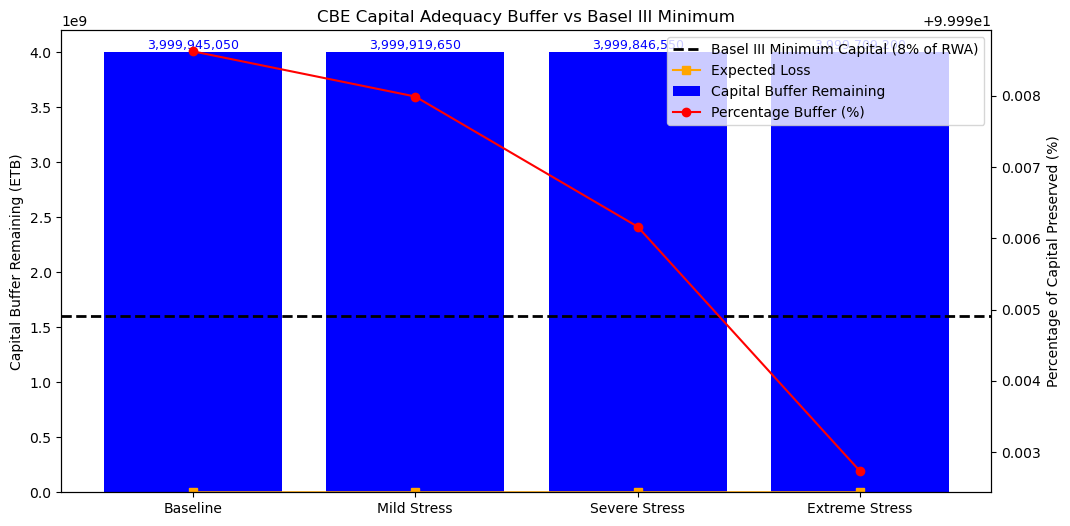

In [39]:
# Step 1: Compute Basel III Minimum Capital
# Capital and RWA assumptions
capital_buffer = 4_000_000_000
RWA = 20_000_000_000

# Basel III minimum capital requirement (8% of RWA)
basel_min_capital = 0.08 * RWA

# Stress scenario losses
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Capital buffer remaining
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Percentage buffer
percentage_buffer = {scenario: (remaining / capital_buffer) * 100 
                     for scenario, remaining in capital_buffer_remaining.items()}

# Build DataFrame
df_resilience = pd.DataFrame({
    'Scenario': portfolio_losses.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Capital_Buffer_Remaining': capital_buffer_remaining.values(),
    'Percentage_Buffer': percentage_buffer.values()
})

# Step 2: Visualization with Basel III Line
fig, ax = plt.subplots(figsize=(12,6))

# Bar chart: Capital buffer remaining
bars = ax.bar(df_resilience['Scenario'], df_resilience['Capital_Buffer_Remaining'], 
              color='blue', label='Capital Buffer Remaining')

# Add labels
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Add horizontal Basel III minimum capital line
ax.axhline(y=basel_min_capital, color='black', linestyle='--', linewidth=2, label='Basel III Minimum Capital (8% of RWA)')

# Overlay expected losses (orange line)
ax.plot(df_resilience['Scenario'], df_resilience['Expected_Loss'], marker='s', color='orange', label='Expected Loss')

# Overlay percentage buffer (red line, scaled to capital)
ax2 = ax.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Percentage_Buffer'], marker='o', color='red', label='Percentage Buffer (%)')
ax2.set_ylabel("Percentage of Capital Preserved (%)")

# Titles and labels
ax.set_ylabel("Capital Buffer Remaining (ETB)")
ax.set_title("CBE Capital Adequacy Buffer vs Basel III Minimum")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax.transAxes)
plt.show()

### Part G: Adding CET1 (4.5%) and Tier 1 (6%) horizontal lines alongside the 8% line

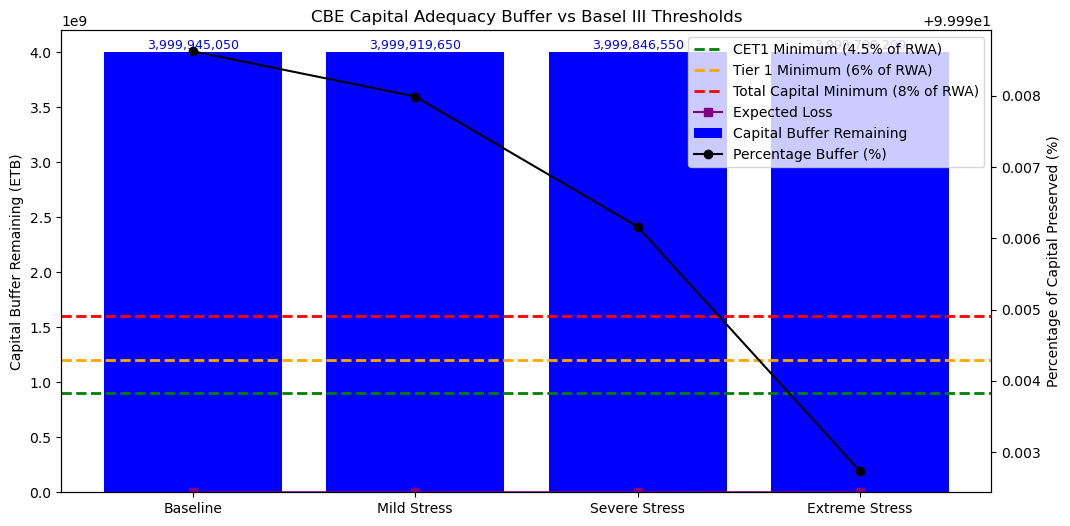

In [40]:
# Step 1: Compute Basel III Minimum Capital Requirements
# Capital and RWA assumptions
capital_buffer = 4_000_000_000
RWA = 20_000_000_000

# Basel III minimum capital requirements
basel_min_cet1 = 0.045 * RWA   # 4.5% of RWA
basel_min_tier1 = 0.06 * RWA   # 6% of RWA
basel_min_total = 0.08 * RWA   # 8% of RWA

# Stress scenario losses
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Capital buffer remaining
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Percentage buffer
percentage_buffer = {scenario: (remaining / capital_buffer) * 100 
                     for scenario, remaining in capital_buffer_remaining.items()}

# Build DataFrame
df_resilience = pd.DataFrame({
    'Scenario': portfolio_losses.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Capital_Buffer_Remaining': capital_buffer_remaining.values(),
    'Percentage_Buffer': percentage_buffer.values()
})

# Step 2: Visualization with Basel III Lines
fig, ax = plt.subplots(figsize=(12,6))

# Bar chart: Capital buffer remaining
bars = ax.bar(df_resilience['Scenario'], df_resilience['Capital_Buffer_Remaining'], 
              color='blue', label='Capital Buffer Remaining')

# Add labels
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height, f'{height:,.0f}', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Add Basel III horizontal lines
ax.axhline(y=basel_min_cet1, color='green', linestyle='--', linewidth=2, label='CET1 Minimum (4.5% of RWA)')
ax.axhline(y=basel_min_tier1, color='orange', linestyle='--', linewidth=2, label='Tier 1 Minimum (6% of RWA)')
ax.axhline(y=basel_min_total, color='red', linestyle='--', linewidth=2, label='Total Capital Minimum (8% of RWA)')

# Overlay expected losses (orange line)
ax.plot(df_resilience['Scenario'], df_resilience['Expected_Loss'], marker='s', color='purple', label='Expected Loss')

# Overlay percentage buffer (red line, scaled to capital)
ax2 = ax.twinx()
ax2.plot(df_resilience['Scenario'], df_resilience['Percentage_Buffer'], marker='o', color='black', label='Percentage Buffer (%)')
ax2.set_ylabel("Percentage of Capital Preserved (%)")

# Titles and labels
ax.set_ylabel("Capital Buffer Remaining (ETB)")
ax.set_title("CBE Capital Adequacy Buffer vs Basel III Thresholds")

# Legends
fig.legend(loc="upper right", bbox_to_anchor=(1,1), bbox_transform=ax.transAxes)
plt.show()

#### Part H: Adding a stacked bar view showing capital vs losses

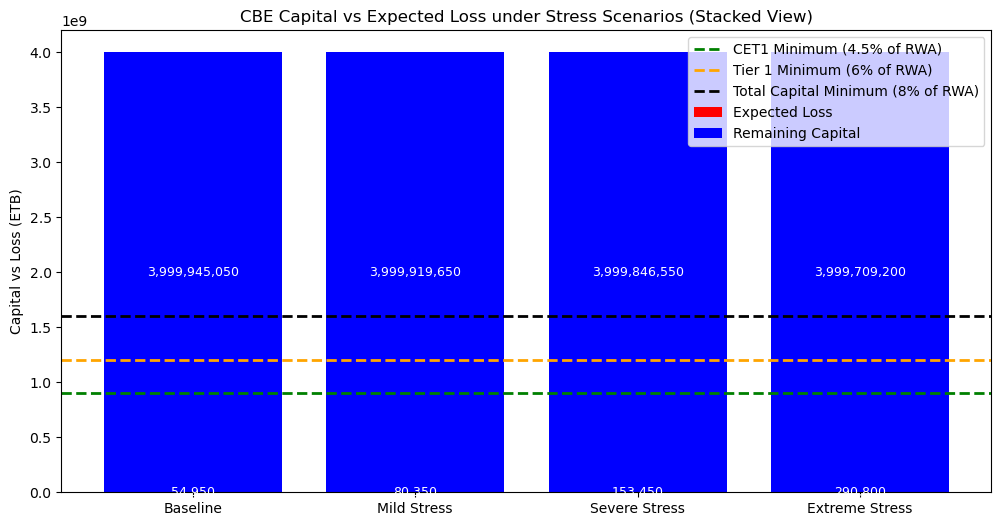

In [41]:
# Capital assumption
capital_buffer = 4_000_000_000

# Stress scenario losses (replace with your actual sums)
portfolio_losses = {
    'Baseline': 54950,
    'Mild Stress': 80350,
    'Severe Stress': 153450,
    'Extreme Stress': 290800
}

# Capital buffer remaining
capital_buffer_remaining = {scenario: capital_buffer - loss for scenario, loss in portfolio_losses.items()}

# Build DataFrame
df_stacked = pd.DataFrame({
    'Scenario': portfolio_losses.keys(),
    'Expected_Loss': portfolio_losses.values(),
    'Remaining_Capital': capital_buffer_remaining.values()
})

# plot
fig, ax = plt.subplots(figsize=(12,6))

# Stacked bars: Expected Loss + Remaining Capital
bars1 = ax.bar(df_stacked['Scenario'], df_stacked['Expected_Loss'], 
               color='red', label='Expected Loss')
bars2 = ax.bar(df_stacked['Scenario'], df_stacked['Remaining_Capital'], 
               bottom=df_stacked['Expected_Loss'], color='blue', label='Remaining Capital')

# Add labels for losses
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height/2, f'{height:,.0f}', 
            ha='center', va='center', fontsize=9, color='white')

# Add labels for remaining capital
for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_y() + height/2, f'{height:,.0f}', 
            ha='center', va='center', fontsize=9, color='white')

# Add Basel III minimum capital lines
RWA = 20_000_000_000
ax.axhline(y=0.045*RWA, color='green', linestyle='--', linewidth=2, label='CET1 Minimum (4.5% of RWA)')
ax.axhline(y=0.06*RWA, color='orange', linestyle='--', linewidth=2, label='Tier 1 Minimum (6% of RWA)')
ax.axhline(y=0.08*RWA, color='black', linestyle='--', linewidth=2, label='Total Capital Minimum (8% of RWA)')

# Titles and labels
ax.set_ylabel("Capital vs Loss (ETB)")
ax.set_title("CBE Capital vs Expected Loss under Stress Scenarios (Stacked View)")
ax.legend()
plt.show()